# Kickstarter campaign success: a historical pre-launch analysis

**Wanyu (Julia) Chen**

Can campaign attributes associated with the launch decision help rank eventual success? This analysis compares input sets and classifiers, then examines calibration, risk concentration, and robustness.

The study uses historical Kickstarter snapshots. Pledged amounts and backer counts are excluded. The timing of the dataset's USD conversion and any later edits to titles/categories is not established, so this is not a verified point-in-time production backtest.

Developed independently as part of Business Analytics Using Python at HEC Paris; curated here as a personal portfolio project. See the repository README for the question, results, data source, and reproduction instructions.

## Reading guide

1. Data, sample construction, and descriptive patterns.
2. A common split, baseline, and candidate models.
3. Cross-validation and the contribution of richer inputs.
4. Held-out results, calibration, and risk ranking.
5. Ablation, bootstrap uncertainty, temporal and sample sensitivity.

All model results below are generated by this notebook. The original exploratory clustering/topic exercises are outside this focused predictive analysis.

# 1. Setup

In [1]:
# Data and plotting libraries.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Models and evaluation tools.
import xgboost as xgb
from sklearn.calibration import calibration_curve
from sklearn.cluster import KMeans
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    silhouette_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
FILE_NAME = "ks-projects-201801.csv"
N_JOBS = 2
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160})


Matplotlib is building the font cache; this may take a moment.


# 2. Load and inspect the data

Download `ks-projects-201801.csv` from [Mickaël Mouillé's dataset](https://www.kaggle.com/datasets/kemical/kickstarter-projects) and place it in `data/raw/`. Raw data are not redistributed. Run this notebook from either the repository root or `notebooks/`.

In [2]:
import hashlib
import json
import platform
import time
from importlib.metadata import version

RUN_STARTED = time.perf_counter()
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "raw" / FILE_NAME
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
if not DATA_PATH.is_file():
    raise FileNotFoundError("Download ks-projects-201801.csv from Kaggle and place it in data/raw/.")
data_path = DATA_PATH
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("Input: data/raw/" + FILE_NAME)
print("SHA-256:", DATA_SHA256)

Input: data/raw/ks-projects-201801.csv
SHA-256: 4846177ce8cfacd06a6acf06cba663b9aa5f5f77e7d0debecf5bdc861a87e3cb


In [3]:
# Read the raw CSV.
raw_data = pd.read_csv(data_path, low_memory=False)

print(f"Raw rows: {raw_data.shape[0]:,}")
print(f"Raw columns: {raw_data.shape[1]}")


Raw rows: 378,661
Raw columns: 15


### What does the original outcome column contain?

In [4]:
# Count every original Kickstarter campaign state.
state_counts = raw_data["state"].value_counts(dropna=False)
display(state_counts)

state
failed        197719
successful    133956
canceled       38779
undefined       3562
live            2799
suspended       1846
Name: count, dtype: int64

The binary target distinguishes successful from failed campaigns. Canceled, suspended, live, and undefined outcomes are excluded from the main sample.

# 3. Prepare the analysis sample

In [5]:
# Keep only campaigns with a completed successful or failed outcome.
data = raw_data.loc[raw_data["state"].isin(["successful", "failed"])].copy()

# Create the prediction target.
# 1 means successful and 0 means failed.
data["success"] = data["state"].eq("successful").astype(int)

# Convert dates and create simple variables known before launch.
data["launched"] = pd.to_datetime(data["launched"])
data["deadline"] = pd.to_datetime(data["deadline"])
data["duration_days"] = (
    data["deadline"] - data["launched"]
).dt.total_seconds().div(86_400)
data["launch_year"] = data["launched"].dt.year.astype(str)
data["launch_month"] = data["launched"].dt.month.astype(str)

# Funding goals are highly skewed, so use log(1 + goal) for modeling.
data["log_goal_usd"] = np.log1p(data["usd_goal_real"])

# Replace the malformed country label with a clear category.
data["country_clean"] = data["country"].replace({'N,0"': "Unknown"})

print(f"Completed campaigns used: {len(data):,}")
print(f"Successful campaigns: {data['success'].sum():,}")
print(f"Historical success rate: {data['success'].mean():.1%}")

Completed campaigns used: 331,675
Successful campaigns: 133,956
Historical success rate: 40.4%


### Check the planned predictors

In [6]:
# These are the variables used in the extended prediction models.
planned_features = [
    "main_category",
    "log_goal_usd",
    "country_clean",
    "currency",
    "duration_days",
    "launch_year",
    "launch_month",
]

# Confirm that the target and planned predictors have no missing values.
missing_values = data[planned_features + ["success"]].isna().sum()
display(missing_values.to_frame("Missing values"))
assert raw_data["ID"].is_unique
assert not missing_values.any()
assert (data["duration_days"] > 0).all()


,Missing values
main_category,0
log_goal_usd,0
country_clean,0
currency,0
duration_days,0
launch_year,0
launch_month,0
success,0


### Feature availability

Pledged amounts, USD pledged amounts, backer counts, and final state are excluded as predictors. Campaign goal, planned duration, calendar variables, country/currency, category, and title length are treated as launch-related attributes.

Two limitations remain: `usd_goal_real` was converted through Fixer.io, but a launch-time exchange rate has not been verified; the snapshot also does not establish that titles and categories are unchanged since launch. These scores should therefore be interpreted as retrospective performance, not a fully point-in-time backtest.

# 4. Historical patterns

These charts describe historical associations. A lower goal may be associated with success without implying that lowering a particular campaign's goal would cause success.

## 4.1 Success rate by main category

In [7]:
category_summary = (
    data.groupby("main_category")
    .agg(
        Campaigns=("ID", "size"),
        Success_rate=("success", "mean"),
    )
    .sort_values("Success_rate", ascending=False)
    .reset_index()
)

display(category_summary.style.format({
    "Campaigns": "{:,.0f}",
    "Success_rate": "{:.1%}",
}))

,main_category,Campaigns,Success_rate
0,Dance,"3,573",65.4%
1,Theater,"10,242",63.8%
2,Comics,"9,878",59.1%
3,Music,"45,949",52.7%
4,Art,"25,641",44.9%
5,Games,"28,521",43.9%
6,Film & Video,"56,527",41.8%
7,Design,"25,364",41.6%
8,Publishing,"35,445",34.7%
9,Photography,"9,689",34.1%


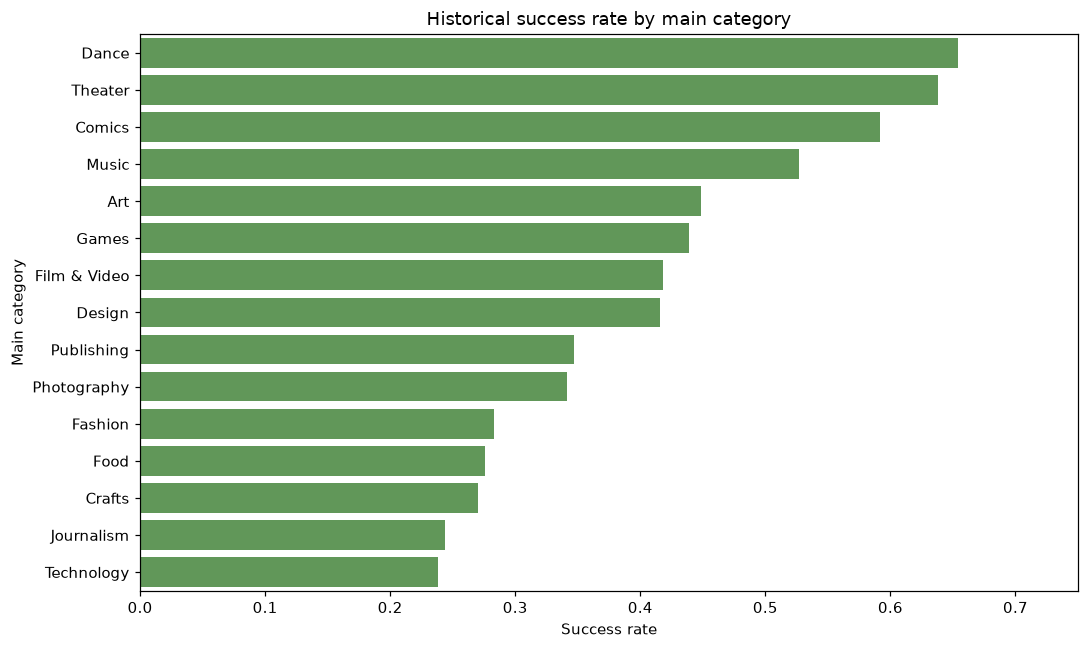

In [8]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=category_summary,
    x="Success_rate",
    y="main_category",
    color="#59A14F",
)
plt.title("Historical success rate by main category")
plt.xlabel("Success rate")
plt.ylabel("Main category")
plt.xlim(0, 0.75)
plt.tight_layout()
plt.show()

## 4.2 Success rate by funding-goal range

In [9]:
# Create dollar ranges that are easy to explain.
goal_bins = [0, 1_000, 5_000, 10_000, 50_000, np.inf]
goal_labels = [
    "Below $1,000",
    "$1,000–$4,999",
    "$5,000–$9,999",
    "$10,000–$49,999",
    "$50,000 or more",
]

data["goal_band"] = pd.cut(
    data["usd_goal_real"],
    bins=goal_bins,
    labels=goal_labels,
    right=False,
)

goal_summary = (
    data.groupby("goal_band", observed=False)
    .agg(
        Campaigns=("ID", "size"),
        Success_rate=("success", "mean"),
    )
    .reset_index()
)

display(goal_summary.style.format({
    "Campaigns": "{:,.0f}",
    "Success_rate": "{:.1%}",
}))

,goal_band,Campaigns,Success_rate
0,"Below $1,000","43,573",55.1%
1,"$1,000–$4,999","102,892",48.5%
2,"$5,000–$9,999","62,329",40.4%
3,"$10,000–$49,999","93,923",32.5%
4,"$50,000 or more","28,958",15.0%


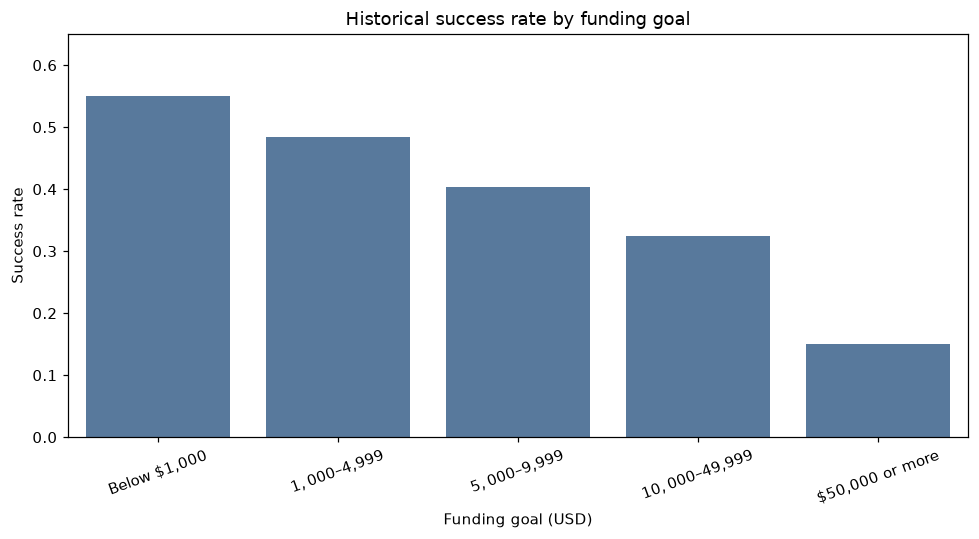

In [10]:
plt.figure(figsize=(9, 5))
sns.barplot(data=goal_summary, x="goal_band", y="Success_rate", color="#4C78A8")
plt.title("Historical success rate by funding goal")
plt.xlabel("Funding goal (USD)")
plt.ylabel("Success rate")
plt.ylim(0, 0.65)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 5. Create one training and test split

The models train on 80% of the campaigns and test on the remaining 20%. `random_state=42` makes the split reproducible. `stratify` keeps the success rate almost identical in both sets.

**No. of campaigns = no. of data entries**

In [11]:
# Split campaign IDs first so every model uses exactly the same campaigns.
train_ids, test_ids = train_test_split(
    data["ID"],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=data["success"],
)

train_rows = data["ID"].isin(train_ids)
test_rows = data["ID"].isin(test_ids)

Y_train = data.loc[train_rows, "success"]
Y_test = data.loc[test_rows, "success"]

print(f"Training campaigns: {len(Y_train):,}")
print(f"Test campaigns: {len(Y_test):,}")
print(f"Training success rate: {Y_train.mean():.1%}")
print(f"Test success rate: {Y_test.mean():.1%}")
assert set(train_ids).isdisjoint(set(test_ids))
assert len(train_ids) + len(test_ids) == len(data)


Training campaigns: 265,340
Test campaigns: 66,335
Training success rate: 40.4%
Test success rate: 40.4%


# 6. Establish a benchmark

Because failure is the most common outcome, the simplest benchmark predicts that **every campaign will fail**.

Any useful model should improve on this benchmark.

In [12]:
benchmark_prediction = np.zeros(len(Y_test), dtype=int)
benchmark_accuracy = accuracy_score(Y_test, benchmark_prediction)

print(f"Benchmark accuracy: {benchmark_accuracy:.4f}")

Benchmark accuracy: 0.5961


## Evaluation metrics

The analysis evaluates every model on the same test data, which was not used to train the models. In this project, a **successful campaign is the positive class**.

- **Accuracy:** The percentage of all campaigns classified correctly. Because 59.6% of campaigns failed, a model could obtain 59.6% accuracy by always predicting failure. The analysis therefore compares accuracy with this benchmark.

- **Precision:** Among the campaigns predicted to succeed, the percentage that actually succeeded. High precision means relatively few unsuccessful campaigns are incorrectly predicted as successful.

- **Recall:** Among all campaigns that actually succeeded, the percentage correctly identified by the model. High recall means the model misses fewer potentially successful campaigns.

- **F1-score:** A single measure that balances precision and recall. It is useful when both false-positive and false-negative predictions matter.

- **ROC-AUC:** Measures how well the model ranks successful campaigns above failed campaigns across all possible classification thresholds. It is not tied only to the default 50% threshold.

  - `0.50` = no better than random ranking  
  - `0.60–0.70` = limited to moderate discrimination  
  - `0.70–0.80` = acceptable discrimination  
  - `1.00` = perfect discrimination  

- **Confusion matrix:** Shows the numbers of correct predictions, false positives, and false negatives.

No single metric provides the complete answer. The analysis uses **ROC-AUC as the main model-selection metric**, while also reporting accuracy, precision, recall, and F1-score to understand the practical prediction errors.

# 7. Logistic regression

Logistic regression is the simplest prediction model in the comparison. We begin with the two variables emphasised in the business question ('**category**' and '**funding goal**'), first separately and then together.

## 7.1 Category encoding

Main-category labels are converted to dummy variables. This historical implementation uses the observed feature vocabulary; a deployment implementation should learn categories within training data and handle unseen values.

In [13]:
category_variable = data["main_category"]

category_dummies = pd.get_dummies(
    category_variable,
    prefix="category",
    dtype=int,
)

display(category_dummies.head())

# Save the names of the newly created dummy columns.
category_columns = category_dummies.columns.tolist()

print(f"Number of category dummy variables: {len(category_columns)}")
print("Category dummy columns:")
print(category_columns)

,category_Art,category_Comics,category_Crafts,category_Dance,category_Design,category_Fashion,category_Film & Video,category_Food,category_Games,category_Journalism,category_Music,category_Photography,category_Publishing,category_Technology,category_Theater
0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
5,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0


Number of category dummy variables: 15
Category dummy columns:
['category_Art', 'category_Comics', 'category_Crafts', 'category_Dance', 'category_Design', 'category_Fashion', 'category_Film & Video', 'category_Food', 'category_Games', 'category_Journalism', 'category_Music', 'category_Photography', 'category_Publishing', 'category_Technology', 'category_Theater']


## Category only

In [14]:
# X contains the category dummy variables.
X_category = category_dummies

# Use the same training and test campaigns created earlier.
X_category_train = X_category.loc[train_rows]
X_category_test = X_category.loc[test_rows]

# Create and train the logistic-regression model.
logit_category = LogisticRegression(max_iter=1000)
logit_category.fit(X_category_train, Y_train)

# Save predictions for the final comparison section.
category_prediction = logit_category.predict(X_category_test)
category_probability = logit_category.predict_proba(X_category_test)[:, 1]

print("Category-only logistic regression fitted. Test results are reserved for section 12.")

Category-only logistic regression fitted. Test results are reserved for section 12.


## 7.2 Funding goal only

In [15]:
X_goal = data[["log_goal_usd"]]
X_goal_train = X_goal.loc[train_rows]
X_goal_test = X_goal.loc[test_rows]

logit_goal = LogisticRegression(max_iter=1000)
logit_goal.fit(X_goal_train, Y_train)

goal_prediction = logit_goal.predict(X_goal_test)
goal_probability = logit_goal.predict_proba(X_goal_test)[:, 1]

print("Funding-goal-only logistic regression fitted. Test results are reserved for section 12.")

Funding-goal-only logistic regression fitted. Test results are reserved for section 12.


## 7.3 Category and funding goal together

In [16]:
# Combine the category dummy variables with the numerical funding goal.
X_core = pd.concat(
    [
        category_dummies,
        data[["log_goal_usd"]],
    ],
    axis=1,
)

X_core_train = X_core.loc[train_rows]
X_core_test = X_core.loc[test_rows]

logit_core = LogisticRegression(max_iter=1000)
logit_core.fit(X_core_train, Y_train)

core_prediction = logit_core.predict(X_core_test)
core_probability = logit_core.predict_proba(X_core_test)[:, 1]

print("Category-and-goal logistic regression fitted. Test results are reserved for section 12.")

Category-and-goal logistic regression fitted. Test results are reserved for section 12.


## 7.4 Extended pre-launch model

The baseline model adds country, currency, planned duration, launch year and month to main category and funding goal. Post-launch outcomes are omitted; see the feature-availability caveat above.

In [17]:
# Select the complete pre-launch feature set.
X_extended = data[[
    "main_category",
    "log_goal_usd",
    "country_clean",
    "currency",
    "duration_days",
    "launch_year",
    "launch_month",
]]

# Convert categorical variables into dummy columns.
X_extended = pd.get_dummies(
    X_extended,
    prefix=["category", "country", "currency", "year", "month"],
    columns=[
        "main_category",
        "country_clean",
        "currency",
        "launch_year",
        "launch_month",
    ],
    dtype=int,
)

X_train = X_extended.loc[train_rows]
X_test = X_extended.loc[test_rows]

logit_extended = LogisticRegression(max_iter=1000)
logit_extended.fit(X_train, Y_train)

extended_prediction = logit_extended.predict(X_test)
extended_probability = logit_extended.predict_proba(X_test)[:, 1]

print("Extended logistic regression fitted. Test results are reserved for section 12.")

Extended logistic regression fitted. Test results are reserved for section 12.


Predictions are saved for the final comparison table. The presentation order reflects the final workflow, not an untouched test-set history.

# 8. Tree models

## 8.1 Decision Tree

In [18]:
# Train one unrestricted Decision Tree, as a flexible reference model.
decision_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
decision_tree.fit(X_train, Y_train)

tree_prediction = decision_tree.predict(X_test)
tree_probability = decision_tree.predict_proba(X_test)[:, 1]

print("Decision Tree fitted. Test results are reserved for section 12.")

Decision Tree fitted. Test results are reserved for section 12.


A single unrestricted tree can follow the training data too closely. This is overfitting: the model learns details that do not generalise well to new campaigns.

## 8.2 Random Forest

In [19]:
# Use 40 trees for the untuned reference forest.
random_forest = RandomForestClassifier(
    n_estimators=40,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)
random_forest.fit(X_train, Y_train)

forest_prediction = random_forest.predict(X_test)
forest_probability = random_forest.predict_proba(X_test)[:, 1]

print("Random Forest fitted. Test results are reserved for section 12.")

Random Forest fitted. Test results are reserved for section 12.


Random Forest combines many trees, which usually reduces the overfitting problem of a single tree. We will later tune a few Random Forest settings using cross-validation.

## 8.3 XGBoost

XGBoost uses a binary logistic objective. The initial depth-4 model is a reference specification; later candidates vary input set, depth, and boosting rounds within the training-sample comparison.

In [20]:
# Convert the data into XGBoost's DMatrix format.
dtrain = xgb.DMatrix(X_train, label=Y_train)
dtest = xgb.DMatrix(X_test, label=Y_test)

params = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "max_depth": 4,
    "eta": 0.1,
    "seed": RANDOM_STATE,
        "nthread": N_JOBS,
}

num_round = 100
xgb_model = xgb.train(params, dtrain, num_round)

# Save probabilities and 0/1 predictions for the final comparison section.
xgb_probability = xgb_model.predict(dtest)
xgb_prediction = (xgb_probability >= 0.50).astype(int)

print("Initial XGBoost model fitted. Test results are reserved for section 12.")

Initial XGBoost model fitted. Test results are reserved for section 12.


# 9. Random Forest hyperparameter tuning


## Hyperparameter search

The forest search compares tree count, maximum depth and minimum split size using five-fold CV ROC-AUC within the training sample. It does not use the held-out outcomes for this search.

In [21]:
# Define the Random Forest and the small parameter grid.
forest_for_tuning = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)

param_grid = {
    "n_estimators": [40, 100],
    "max_depth": [10, 20],
    "min_samples_split": [2, 10],
}

grid_search = GridSearchCV(
    forest_for_tuning,
    param_grid,
    cv=5,
    scoring="roc_auc",
    verbose=1,
)

grid_search.fit(X_train, Y_train)

print("Best Random Forest settings:")
print(grid_search.best_params_)
print(f"Best cross-validation ROC-AUC: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 8 candidates, totalling 40 fits


Best Random Forest settings:
{'max_depth': 20, 'min_samples_split': 10, 'n_estimators': 100}
Best cross-validation ROC-AUC: 0.7175


### All Random Forest tuning results

The table below reports every parameter combination considered by `GridSearchCV`. This is the code output used for Appendix Table A1.

In [22]:
# Put every tested parameter combination and its validation score in one table.
grid_search_results = pd.DataFrame(grid_search.cv_results_)[[
    "param_n_estimators",
    "param_max_depth",
    "param_min_samples_split",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]].copy()

grid_search_results = grid_search_results.rename(columns={
    "param_n_estimators": "Number of trees",
    "param_max_depth": "Maximum depth",
    "param_min_samples_split": "Minimum samples to split",
    "mean_test_score": "Mean CV ROC_AUC",
    "std_test_score": "CV standard deviation",
    "rank_test_score": "Rank",
}).sort_values("Rank")

display(grid_search_results.style.format({
    "Mean CV ROC_AUC": "{:.4f}",
    "CV standard deviation": "{:.4f}",
}))

,Number of trees,Maximum depth,Minimum samples to split,Mean CV ROC_AUC,CV standard deviation,Rank
7,100,20,10,0.7175,0.0014,1
6,40,20,10,0.7158,0.0015,2
5,100,20,2,0.7157,0.0009,3
4,40,20,2,0.7132,0.0010,4
1,100,10,2,0.7016,0.0017,5
3,100,10,10,0.7011,0.0024,6
0,40,10,2,0.7000,0.0018,7
2,40,10,10,0.6999,0.0024,8


In [23]:
# GridSearchCV automatically refits the selected Random Forest on all training data.
tuned_forest = grid_search.best_estimator_
tuned_forest_prediction = tuned_forest.predict(X_test)
tuned_forest_probability = tuned_forest.predict_proba(X_test)[:, 1]

print("Tuned Random Forest fitted. Test results are reserved for section 12.")

Tuned Random Forest fitted. Test results are reserved for section 12.


## Training versus test accuracy: checking for overfitting

A model may perform very well on the data used to train it but much worse on new data. A large difference between training and test accuracy therefore suggests overfitting.

The analysis compares the unrestricted Decision Tree with the tuned Random Forest.

In [24]:
# Compare training and test accuracy to check for overfitting.

overfitting_check = pd.DataFrame({
    "Model": [
        "Unrestricted Decision Tree",
        "Tuned Random Forest",
    ],
    "Training accuracy": [
        accuracy_score(
            Y_train,
            decision_tree.predict(X_train),
        ),
        accuracy_score(
            Y_train,
            tuned_forest.predict(X_train),
        ),
    ],
    "Test accuracy": [
        accuracy_score(Y_test, tree_prediction),
        accuracy_score(Y_test, tuned_forest_prediction),
    ],
})

# Calculate how much performance falls on new data.
overfitting_check["Training–test gap"] = (
    overfitting_check["Training accuracy"]
    - overfitting_check["Test accuracy"]
)

display(
    overfitting_check.style.format({
        "Training accuracy": "{:.1%}",
        "Test accuracy": "{:.1%}",
        "Training–test gap": "{:.1%}",
    })
)

# Print the results in the same format used on the presentation slide.
for _, row in overfitting_check.iterrows():
    print(
        f"{row['Model']}: "
        f"{row['Training accuracy']:.0%} → "
        f"{row['Test accuracy']:.0%}"
    )

,Model,Training accuracy,Test accuracy,Training–test gap
0,Unrestricted Decision Tree,100.0%,59.8%,40.2%
1,Tuned Random Forest,72.0%,66.9%,5.1%


Unrestricted Decision Tree: 100% → 60%
Tuned Random Forest: 72% → 67%


This tuning step chooses the Random Forest settings using only the training sample. The tuned forest can now enter the broader cross-validation shortlist alongside logistic regression and XGBoost.


# 10. Add sub-category and campaign-title features


## 10.1 Why the sub-category matters

`main_category` groups very different projects. The sub-category (`category` column, 159 values) is chosen by the creator before launch. Within the same main category, historical success rates can differ substantially (considering sub-categories with at least 500 campaigns):


In [25]:
# Success rate of every sub-category with at least 500 campaigns.
sub_summary = (
    data.groupby(["main_category", "category"])
    .agg(Campaigns=("ID", "size"), Success_rate=("success", "mean"))
    .query("Campaigns >= 500")
    .reset_index()
)

# Largest gaps between sub-categories of the same main category.
gaps = sub_summary.groupby("main_category")["Success_rate"].agg(["min", "max"])
gaps["gap"] = gaps["max"] - gaps["min"]
display(gaps.sort_values("gap", ascending=False).head(5).style.format("{:.1%}"))

for cat in ["Games", "Music", "Technology"]:
    rows = sub_summary[sub_summary["main_category"] == cat].sort_values("Success_rate")
    print(f"{cat}: lowest {rows.iloc[0]['category']} ({rows.iloc[0]['Success_rate']:.0%}), "
          f"highest {rows.iloc[-1]['category']} ({rows.iloc[-1]['Success_rate']:.0%})")

,min,max,gap
main_category,,,
Games,10.6%,67.0%,56.4%
Music,17.4%,67.9%,50.5%
Technology,7.1%,52.3%,45.2%
Film & Video,17.2%,58.6%,41.3%
Publishing,24.2%,54.9%,30.7%


Games: lowest Mobile Games (11%), highest Tabletop Games (67%)
Music: lowest Hip-Hop (17%), highest Indie Rock (68%)
Technology: lowest Apps (7%), highest DIY Electronics (52%)


## 10.2 Title features and expanded inputs

Two simple title measures - character count and word count - are added alongside sub-category indicators. Titles exist before launch, but the snapshot does not verify that their recorded values are the original launch-time values.

In [26]:
name = data["name"].fillna("").astype(str)
data["name_chars"] = name.str.len()
data["name_words"] = name.str.split().str.len().fillna(0).astype(int)

X_original = X_extended
X_expanded = pd.concat(
    [
        X_extended,
        pd.get_dummies(data["category"], prefix="sub_category", dtype=int),
        data[["name_chars", "name_words"]],
    ],
    axis=1,
)
print(f"Original pre-launch inputs: {X_original.shape[1]}")
print(f"Expanded pre-launch inputs: {X_expanded.shape[1]}")

Original pre-launch inputs: 75
Expanded pre-launch inputs: 236


# 11. Select the final model with five-fold cross-validation


## 11.1 Compare candidates on the training sample

Each candidate uses the same five stratified folds. The selection metric is mean ROC-AUC. These are non-nested selection scores; they do not account for the full search and earlier feature-development history.

In [27]:
# Use the same five folds for every candidate so that the comparison is fair.
folds = list(StratifiedKFold(n_splits=5).split(np.zeros(train_rows.sum()), Y_train))


def xgb_fit_predict(Xa, ya, Xb, depth=4, rounds=100):
    params = {
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "max_depth": depth,
        "eta": 0.1,
        "seed": RANDOM_STATE,
        "nthread": N_JOBS,
    }
    model = xgb.train(params, xgb.DMatrix(Xa, label=ya), rounds)
    return model.predict(xgb.DMatrix(Xb))


def logit_fit_predict(Xa, ya, Xb):
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    return model.fit(Xa, ya).predict_proba(Xb)[:, 1]


def forest_fit_predict(Xa, ya, Xb):
    # Use the settings selected by GridSearchCV in section 9.
    forest = RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_split=10,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    )
    return forest.fit(Xa, ya).predict_proba(Xb)[:, 1]


def cross_validated_auc(fit_predict, X):
    X_tr = X.loc[train_rows].reset_index(drop=True)
    y_tr = Y_train.reset_index(drop=True)
    scores = [
        roc_auc_score(
            y_tr.iloc[validation_indices],
            fit_predict(
                X_tr.iloc[training_indices],
                y_tr.iloc[training_indices],
                X_tr.iloc[validation_indices],
            ),
        )
        for training_indices, validation_indices in folds
    ]
    return np.mean(scores), np.std(scores)


candidates = {
    "Logistic regression | original inputs": (logit_fit_predict, X_original),
    "Tuned Random Forest | original inputs": (forest_fit_predict, X_original),
    "XGBoost depth 8 | original inputs": (
        lambda a, b, c: xgb_fit_predict(a, b, c, depth=8, rounds=300),
        X_original,
    ),
    "XGBoost depth 4 | original inputs": (
        lambda a, b, c: xgb_fit_predict(a, b, c, depth=4, rounds=100),
        X_original,
    ),
    "XGBoost depth 6 | original inputs": (
        lambda a, b, c: xgb_fit_predict(a, b, c, depth=6, rounds=300),
        X_original,
    ),
    "Logistic regression | expanded inputs": (logit_fit_predict, X_expanded),
    "Tuned Random Forest | expanded inputs": (forest_fit_predict, X_expanded),
    "XGBoost depth 4 | expanded inputs": (
        lambda a, b, c: xgb_fit_predict(a, b, c, depth=4, rounds=100),
        X_expanded,
    ),
    "XGBoost depth 6 | expanded inputs": (
        lambda a, b, c: xgb_fit_predict(a, b, c, depth=6, rounds=300),
        X_expanded,
    ),
    "XGBoost depth 8 | expanded inputs": (
        lambda a, b, c: xgb_fit_predict(a, b, c, depth=8, rounds=300),
        X_expanded,
    ),
}

cv_rows = []
for label, (fit_predict, X) in candidates.items():
    mean_auc, standard_deviation = cross_validated_auc(fit_predict, X)
    cv_rows.append({
        "Candidate": label,
        "CV ROC_AUC": mean_auc,
        "Standard deviation": standard_deviation,
    })
    print(f"{label:45s} {mean_auc:.4f} ± {standard_deviation:.4f}")

cv_results = pd.DataFrame(cv_rows).sort_values("CV ROC_AUC", ascending=False)
display(cv_results.style.format({
    "CV ROC_AUC": "{:.4f}",
    "Standard deviation": "{:.4f}",
}))

Logistic regression | original inputs         0.6912 ± 0.0009


Tuned Random Forest | original inputs         0.7175 ± 0.0014


XGBoost depth 8 | original inputs             0.7312 ± 0.0009


XGBoost depth 4 | original inputs             0.7224 ± 0.0011


XGBoost depth 6 | original inputs             0.7326 ± 0.0010


Logistic regression | expanded inputs         0.7324 ± 0.0013


Tuned Random Forest | expanded inputs         0.7415 ± 0.0016


XGBoost depth 4 | expanded inputs             0.7465 ± 0.0016


XGBoost depth 6 | expanded inputs             0.7597 ± 0.0011


XGBoost depth 8 | expanded inputs             0.7613 ± 0.0013


,Candidate,CV ROC_AUC,Standard deviation
9,XGBoost depth 8 | expanded inputs,0.7613,0.0013
8,XGBoost depth 6 | expanded inputs,0.7597,0.0011
7,XGBoost depth 4 | expanded inputs,0.7465,0.0016
6,Tuned Random Forest | expanded inputs,0.7415,0.0016
4,XGBoost depth 6 | original inputs,0.7326,0.0010
5,Logistic regression | expanded inputs,0.7324,0.0013
2,XGBoost depth 8 | original inputs,0.7312,0.0009
3,XGBoost depth 4 | original inputs,0.7224,0.0011
1,Tuned Random Forest | original inputs,0.7175,0.0014
0,Logistic regression | original inputs,0.6912,0.0009


## 11.2 Separate the value of the algorithm from the value of the inputs

To make the comparison easier to interpret, we evaluate Logistic Regression, Random Forest, and XGBoost with both the original and expanded input sets. Every number below comes from the same five training folds.

In [28]:
# Compare the same three algorithms using the original and expanded inputs.
# These are cross-validation results from the training sample only.
controlled_candidates = [
    "Logistic regression | original inputs",
    "Logistic regression | expanded inputs",
    "Tuned Random Forest | original inputs",
    "Tuned Random Forest | expanded inputs",
    "XGBoost depth 8 | original inputs",
    "XGBoost depth 8 | expanded inputs",
]

controlled_comparison = (
    cv_results.set_index("Candidate")
    .loc[controlled_candidates]
    .reset_index()
)
controlled_comparison[["Algorithm", "Input set"]] = (
    controlled_comparison["Candidate"]
    .str.split(r" \| ", n=1, expand=True)
)
controlled_comparison = controlled_comparison[[
    "Algorithm", "Input set", "CV ROC_AUC", "Standard deviation"
]]

display(controlled_comparison.style.format({
    "CV ROC_AUC": "{:.4f}",
    "Standard deviation": "{:.4f}",
}))

,Algorithm,Input set,CV ROC_AUC,Standard deviation
0,Logistic regression,original inputs,0.6912,0.0009
1,Logistic regression,expanded inputs,0.7324,0.0013
2,Tuned Random Forest,original inputs,0.7175,0.0014
3,Tuned Random Forest,expanded inputs,0.7415,0.0016
4,XGBoost depth 8,original inputs,0.7312,0.0009
5,XGBoost depth 8,expanded inputs,0.7613,0.0013


The controlled comparison separates richer inputs from model flexibility. Both contribute predictive gains. Fold-to-fold standard deviations describe variation across these folds, not uncertainty from the full model-selection process.

## 11.3 Fit the selected model and evaluate it on the test set


In [29]:
# Select the candidate with the highest average cross-validation ROC-AUC.
selected_model_name = cv_results.iloc[0]["Candidate"]
selected_fit_predict, X_selected = candidates[selected_model_name]

# Fit it on the complete training sample and evaluate it once on the held-out test sample.
final_probability = selected_fit_predict(
    X_selected.loc[train_rows],
    Y_train,
    X_selected.loc[test_rows],
)
final_prediction = (final_probability >= 0.50).astype(int)

print(f"Selected through cross-validation: {selected_model_name}")
print(f"Held-out test ROC-AUC: {roc_auc_score(Y_test, final_probability):.4f}")
print(classification_report(
    Y_test,
    final_prediction,
    target_names=["Failed", "Successful"],
))

Selected through cross-validation: XGBoost depth 8 | expanded inputs
Held-out test ROC-AUC: 0.7609
              precision    recall  f1-score   support

      Failed       0.73      0.79      0.76     39544
  Successful       0.65      0.56      0.60     26791

    accuracy                           0.70     66335
   macro avg       0.69      0.68      0.68     66335
weighted avg       0.69      0.70      0.69     66335



# 12. Final performance comparison


## 12.1 Fit the remaining report-comparison models

The following two models were already assessed during cross-validation. We now fit them on the complete training sample so their held-out results can be reproduced in the final comparison table.

In [30]:
# Expanded logistic regression.
expanded_logit_probability = logit_fit_predict(
    X_expanded.loc[train_rows],
    Y_train,
    X_expanded.loc[test_rows],
)
expanded_logit_prediction = (expanded_logit_probability >= 0.50).astype(int)

# Expanded XGBoost using the original depth-4 specification.
expanded_xgb_depth4_probability = xgb_fit_predict(
    X_expanded.loc[train_rows],
    Y_train,
    X_expanded.loc[test_rows],
    depth=4,
    rounds=100,
)
expanded_xgb_depth4_prediction = (
    expanded_xgb_depth4_probability >= 0.50
).astype(int)

print("Additional comparison models fitted on the complete training sample.")

Additional comparison models fitted on the complete training sample.


## 12.2 Compare all models on the held-out test sample

In [31]:
# Compare the saved model predictions on the same held-out test campaigns.
# These results are presented only after the final specification has been selected by cross-validation.
model_results = pd.DataFrame([
    {
        "Model": "Majority-class benchmark",
        "Accuracy": accuracy_score(Y_test, benchmark_prediction),
        "Precision": precision_score(Y_test, benchmark_prediction, zero_division=0),
        "Recall": recall_score(Y_test, benchmark_prediction, zero_division=0),
        "F1": f1_score(Y_test, benchmark_prediction, zero_division=0),
        "ROC_AUC": 0.5,
    },
    {
        "Model": "Logistic: category only",
        "Accuracy": accuracy_score(Y_test, category_prediction),
        "Precision": precision_score(Y_test, category_prediction),
        "Recall": recall_score(Y_test, category_prediction),
        "F1": f1_score(Y_test, category_prediction),
        "ROC_AUC": roc_auc_score(Y_test, category_probability),
    },
    {
        "Model": "Logistic: goal only",
        "Accuracy": accuracy_score(Y_test, goal_prediction),
        "Precision": precision_score(Y_test, goal_prediction),
        "Recall": recall_score(Y_test, goal_prediction),
        "F1": f1_score(Y_test, goal_prediction),
        "ROC_AUC": roc_auc_score(Y_test, goal_probability),
    },
    {
        "Model": "Logistic: category + goal",
        "Accuracy": accuracy_score(Y_test, core_prediction),
        "Precision": precision_score(Y_test, core_prediction),
        "Recall": recall_score(Y_test, core_prediction),
        "F1": f1_score(Y_test, core_prediction),
        "ROC_AUC": roc_auc_score(Y_test, core_probability),
    },
    {
        "Model": "Logistic: original inputs",
        "Accuracy": accuracy_score(Y_test, extended_prediction),
        "Precision": precision_score(Y_test, extended_prediction),
        "Recall": recall_score(Y_test, extended_prediction),
        "F1": f1_score(Y_test, extended_prediction),
        "ROC_AUC": roc_auc_score(Y_test, extended_probability),
    },
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(Y_test, tree_prediction),
        "Precision": precision_score(Y_test, tree_prediction),
        "Recall": recall_score(Y_test, tree_prediction),
        "F1": f1_score(Y_test, tree_prediction),
        "ROC_AUC": roc_auc_score(Y_test, tree_probability),
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(Y_test, forest_prediction),
        "Precision": precision_score(Y_test, forest_prediction),
        "Recall": recall_score(Y_test, forest_prediction),
        "F1": f1_score(Y_test, forest_prediction),
        "ROC_AUC": roc_auc_score(Y_test, forest_probability),
    },
    {
        "Model": "Tuned Random Forest",
        "Accuracy": accuracy_score(Y_test, tuned_forest_prediction),
        "Precision": precision_score(Y_test, tuned_forest_prediction),
        "Recall": recall_score(Y_test, tuned_forest_prediction),
        "F1": f1_score(Y_test, tuned_forest_prediction),
        "ROC_AUC": roc_auc_score(Y_test, tuned_forest_probability),
    },
    {
        "Model": "Initial XGBoost",
        "Accuracy": accuracy_score(Y_test, xgb_prediction),
        "Precision": precision_score(Y_test, xgb_prediction),
        "Recall": recall_score(Y_test, xgb_prediction),
        "F1": f1_score(Y_test, xgb_prediction),
        "ROC_AUC": roc_auc_score(Y_test, xgb_probability),
    },
    {
        "Model": "Logistic: expanded inputs",
        "Accuracy": accuracy_score(Y_test, expanded_logit_prediction),
        "Precision": precision_score(Y_test, expanded_logit_prediction),
        "Recall": recall_score(Y_test, expanded_logit_prediction),
        "F1": f1_score(Y_test, expanded_logit_prediction),
        "ROC_AUC": roc_auc_score(Y_test, expanded_logit_probability),
    },
    {
        "Model": "XGBoost depth 4: expanded inputs",
        "Accuracy": accuracy_score(Y_test, expanded_xgb_depth4_prediction),
        "Precision": precision_score(Y_test, expanded_xgb_depth4_prediction),
        "Recall": recall_score(Y_test, expanded_xgb_depth4_prediction),
        "F1": f1_score(Y_test, expanded_xgb_depth4_prediction),
        "ROC_AUC": roc_auc_score(Y_test, expanded_xgb_depth4_probability),
    },
    {
        "Model": "Selected XGBoost with expanded inputs",
        "Accuracy": accuracy_score(Y_test, final_prediction),
        "Precision": precision_score(Y_test, final_prediction),
        "Recall": recall_score(Y_test, final_prediction),
        "F1": f1_score(Y_test, final_prediction),
        "ROC_AUC": roc_auc_score(Y_test, final_probability),
    },
])

display(model_results.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Majority-class benchmark,0.596,0.000,0.000,0.000,0.500
1,Logistic: category only,0.619,0.555,0.291,0.382,0.622
2,Logistic: goal only,0.609,0.535,0.253,0.344,0.629
3,Logistic: category + goal,0.636,0.576,0.380,0.458,0.671
4,Logistic: original inputs,0.654,0.601,0.427,0.499,0.690
5,Decision Tree,0.598,0.502,0.509,0.505,0.583
6,Random Forest,0.631,0.550,0.481,0.513,0.662
7,Tuned Random Forest,0.669,0.630,0.436,0.515,0.718
8,Initial XGBoost,0.670,0.622,0.466,0.532,0.720
9,Logistic: expanded inputs,0.677,0.623,0.504,0.557,0.730


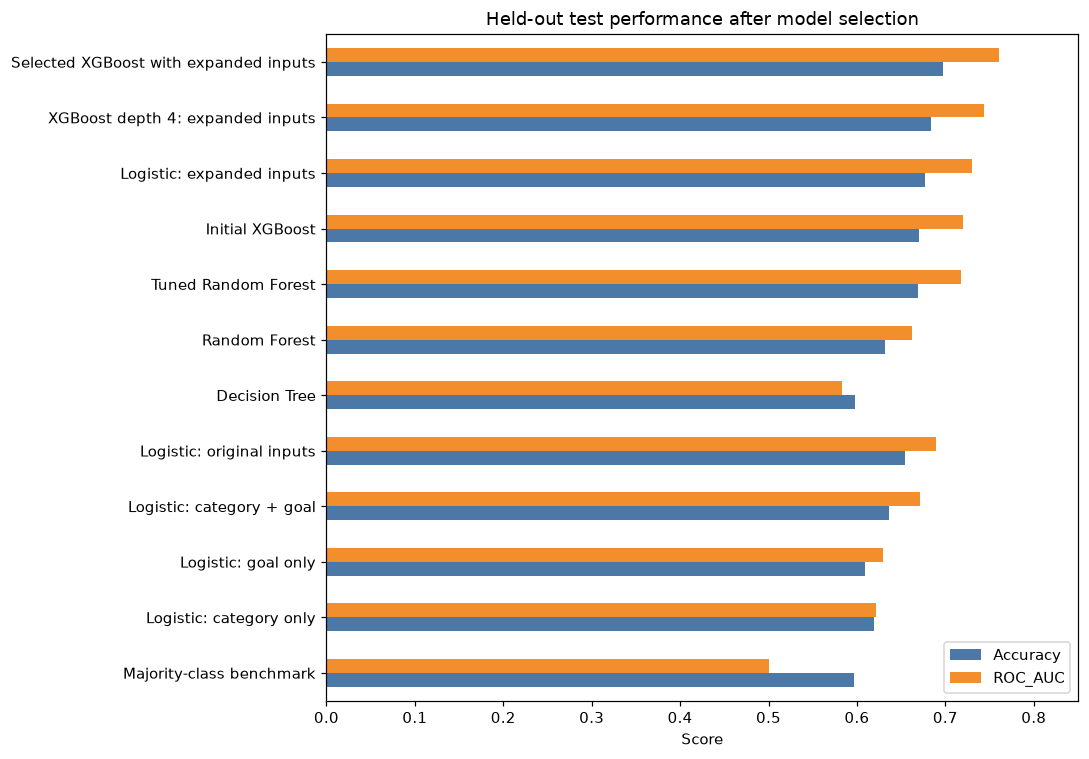

In [32]:
# Show accuracy and ROC-AUC together for a concise visual comparison.
plot_results = model_results.set_index("Model")[["Accuracy", "ROC_AUC"]]
ax = plot_results.plot(
    kind="barh",
    figsize=(10, 7),
    color=["#4C78A8", "#F28E2B"],
)
ax.set_title("Held-out test performance after model selection")
ax.set_xlabel("Score")
ax.set_ylabel("")
ax.set_xlim(0, 0.85)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

The comparison distinguishes baseline and expanded inputs. A score difference between models with different input sets cannot be attributed solely to the algorithm. These test scores belong to the historical development workflow, in which early model results had already been examined; reordering their presentation does not make the test set a newly untouched holdout.

## 12.3 Are the predicted probabilities well calibrated?

ROC-AUC measures ranking, but the business application also uses the size of each predicted probability. Calibration asks whether campaigns assigned a probability near 60%, for example, succeed approximately 60% of the time.

Brier score: 0.1932
Calibration intercept: -0.001
Calibration slope: 1.008


,Average predicted probability,Observed success rate
0,5.8%,4.9%
1,15.2%,14.6%
2,23.1%,23.1%
3,30.2%,29.7%
4,36.7%,37.5%
5,43.1%,43.0%
6,49.8%,51.8%
7,57.2%,57.3%
8,65.5%,65.6%
9,77.9%,76.3%


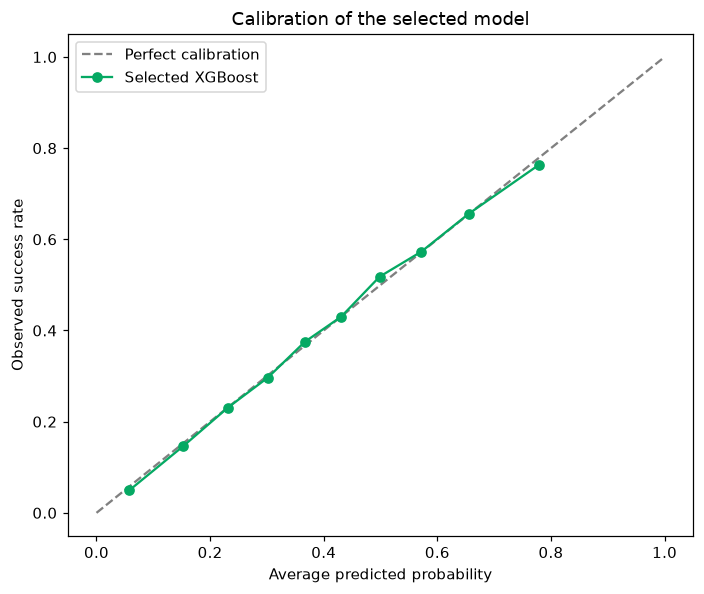

In [33]:
# Brier score is the mean squared difference between predicted probabilities
# and the observed 0/1 outcomes. Lower values indicate better probability accuracy.
final_brier_score = brier_score_loss(Y_test, final_probability)

# Compare average predictions with observed success rates in ten equally sized groups.
observed_rate, predicted_rate = calibration_curve(
    Y_test,
    final_probability,
    n_bins=10,
    strategy="quantile",
)
calibration_table = pd.DataFrame({
    "Average predicted probability": predicted_rate,
    "Observed success rate": observed_rate,
})

# A calibration slope close to 1 indicates appropriately spread probabilities.
safe_probability = np.clip(final_probability, 1e-6, 1 - 1e-6)
prediction_log_odds = np.log(
    safe_probability / (1 - safe_probability)
).reshape(-1, 1)
calibration_model = LogisticRegression(C=np.inf, max_iter=1000)
calibration_model.fit(prediction_log_odds, Y_test)
calibration_intercept = calibration_model.intercept_[0]
calibration_slope = calibration_model.coef_[0, 0]

print(f"Brier score: {final_brier_score:.4f}")
print(f"Calibration intercept: {calibration_intercept:.3f}")
print(f"Calibration slope: {calibration_slope:.3f}")
display(calibration_table.style.format("{:.1%}"))

plt.figure(figsize=(6.5, 5.5))
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect calibration")
plt.plot(predicted_rate, observed_rate, marker="o", color="#05A963", label="Selected XGBoost")
plt.xlabel("Average predicted probability")
plt.ylabel("Observed success rate")
plt.title("Calibration of the selected model")
plt.legend()
plt.tight_layout()
plt.show()

The calibration curve is evaluated on the held-out historical test sample. It indicates how usable the probabilities are for ranking and prioritising campaigns; it does not guarantee identical calibration for future cohorts.

# 13. Interpret the selected model


## 13.2 Translate performance into 1,000 campaigns


In [34]:
tn, fp, fn, tp = confusion_matrix(Y_test, final_prediction).ravel()

confusion_per_1000 = pd.DataFrame({
    "Outcome": [
        "Correctly predicted failure",
        "Incorrectly predicted success",
        "Incorrectly predicted failure",
        "Correctly predicted success",
    ],
    "Approximate campaigns per 1,000": np.round(
        np.array([tn, fp, fn, tp]) / len(Y_test) * 1000
    ).astype(int),
})

display(confusion_per_1000)

,Outcome,"Approximate campaigns per 1,000"
0,Correctly predicted failure,473
1,Incorrectly predicted success,123
2,Incorrectly predicted failure,179
3,Correctly predicted success,225


This example makes the limitation concrete. The model adds useful information, but it still makes mistakes.

## 13.3 Category and funding goal together


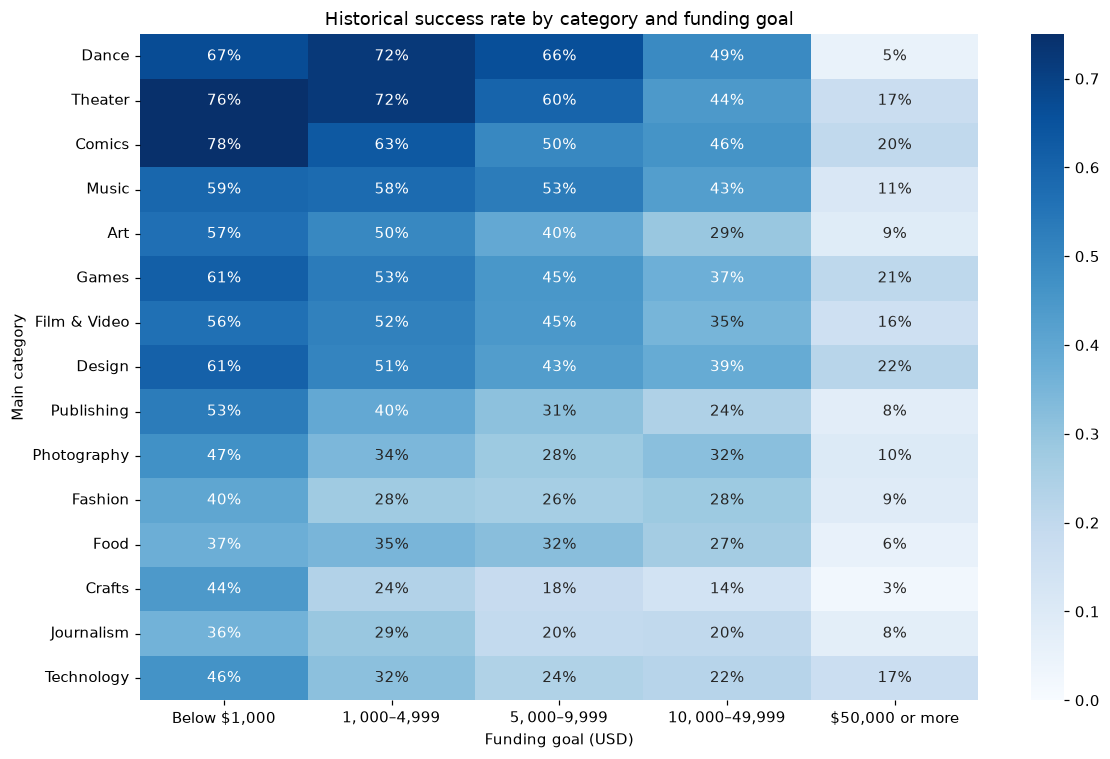

In [35]:
# Calculate historical success rates for each category and goal band.
category_goal_table = data.pivot_table(
    index="main_category",
    columns="goal_band",
    values="success",
    aggfunc="mean",
    observed=False,
)

# Order categories from highest to lowest overall success rate.
category_goal_table = category_goal_table.loc[category_summary["main_category"]]

plt.figure(figsize=(11, 7))
sns.heatmap(
    category_goal_table,
    annot=True,
    fmt=".0%",
    cmap="Blues",
    vmin=0,
    vmax=0.75,
)
plt.title("Historical success rate by category and funding goal")
plt.xlabel("Funding goal (USD)")
plt.ylabel("Main category")
plt.tight_layout()
plt.show()

The heatmap can help a platform identify groups that historically struggled and may benefit from additional guidance. It should not be used to tell creators that changing category or goal alone will cause success.

## 13.4 Grouped feature importance


Final-model accuracy: 0.6978
Final-model ROC-AUC: 0.7609


,Feature,Total_gain
0,log_goal_usd,115011.648438
1,duration_days,72862.023438
235,name_words,25585.349609
234,name_chars,19305.648438
211,sub_category_Tabletop Games,15400.003906
12,category_Music,8138.647949
16,category_Theater,7759.028809
143,sub_category_Hip-Hop,6441.206055
60,year_2015,5890.996094
83,sub_category_Apps,5873.313477


,Input_group,Share
0,Funding goal,27.7%
1,Sub-category,19.3%
2,Campaign duration,17.5%
3,Main category,12.1%
4,Title length,10.8%
5,Launch year,6.2%
6,Launch month,3.6%
7,Country,1.9%
8,Currency,0.9%


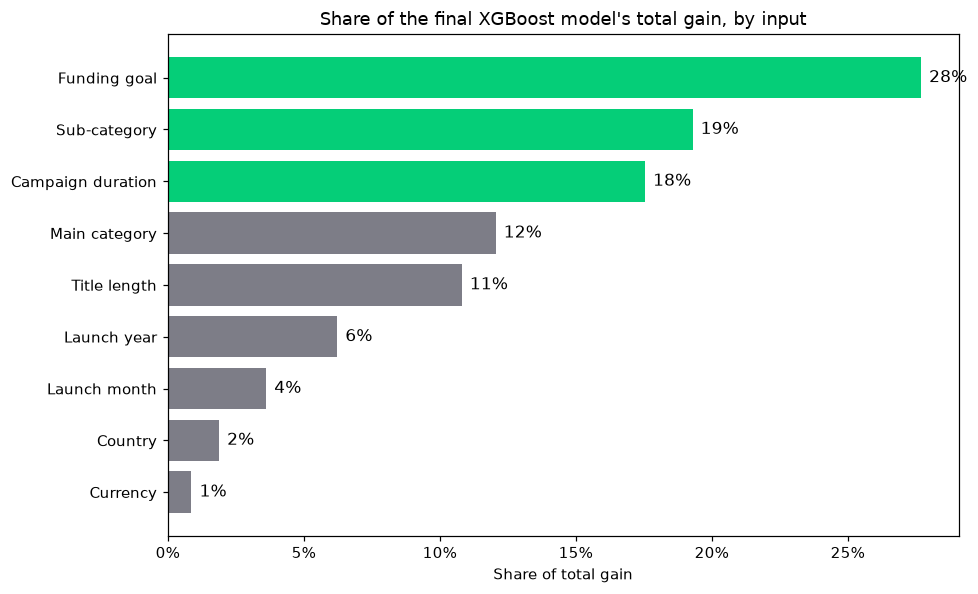

In [36]:
# Grouped feature importance for the final selected XGBoost
# 

X_final_train = X_expanded.loc[train_rows]
X_final_test = X_expanded.loc[test_rows]

# Convert the data into XGBoost's DMatrix format.
dtrain_final = xgb.DMatrix(
    X_final_train,
    label=Y_train,
    feature_names=X_final_train.columns.tolist(),
)

dtest_final = xgb.DMatrix(
    X_final_test,
    label=Y_test,
    feature_names=X_final_test.columns.tolist(),
)

final_params = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "max_depth": 8,
    "eta": 0.1,
    "seed": RANDOM_STATE,
        "nthread": N_JOBS,
}

final_xgb_model = xgb.train(
    params=final_params,
    dtrain=dtrain_final,
    num_boost_round=300,
)

final_probability_check = final_xgb_model.predict(dtest_final)
final_prediction_check = (final_probability_check >= 0.50).astype(int)

print(
    "Final-model accuracy:",
    round(accuracy_score(Y_test, final_prediction_check), 4),
)

print(
    "Final-model ROC-AUC:",
    round(roc_auc_score(Y_test, final_probability_check), 4),
)
#
# Total gain measures the total improvement in the model's decisions
# produced by splits involving that feature.
raw_importance = final_xgb_model.get_score(
    importance_type="total_gain"
)

feature_importance = pd.DataFrame({
    "Feature": X_final_train.columns,
})

# Features that XGBoost never uses will not appear in raw_importance.
# Give those features an importance of zero.
feature_importance["Total_gain"] = (
    feature_importance["Feature"]
    .map(raw_importance)
    .fillna(0)
)

display(
    feature_importance
    .sort_values("Total_gain", ascending=False)
    .head(20)
)
def assign_feature_group(feature_name):

    # Check sub-category before main category.
    if feature_name.startswith("sub_category_"):
        return "Sub-category"

    elif feature_name == "log_goal_usd":
        return "Funding goal"

    elif feature_name == "duration_days":
        return "Campaign duration"

    elif feature_name.startswith("category_"):
        return "Main category"

    elif feature_name in ["name_chars", "name_words"]:
        return "Title length"

    elif feature_name.startswith("year_"):
        return "Launch year"

    elif feature_name.startswith("month_"):
        return "Launch month"

    elif feature_name.startswith("country_"):
        return "Country"

    elif feature_name.startswith("currency_"):
        return "Currency"

    else:
        return "Other"


feature_importance["Input_group"] = (
    feature_importance["Feature"]
    .apply(assign_feature_group)
)

grouped_importance = (
    feature_importance
    .groupby("Input_group", as_index=False)["Total_gain"]
    .sum()
)

# Convert each group's gain into a share of the model's total gain.
grouped_importance["Share"] = (
    grouped_importance["Total_gain"]
    / grouped_importance["Total_gain"].sum()
)

grouped_importance = (
    grouped_importance
    .sort_values("Share", ascending=False)
    .reset_index(drop=True)
)

# Display a compact table.
importance_table = grouped_importance[
    ["Input_group", "Share"]
].copy()

importance_table["Share"] = importance_table["Share"].map(
    lambda value: f"{value:.1%}"
)

display(importance_table)
plt.figure(figsize=(9, 5.5))

plot_data = grouped_importance.sort_values(
    "Share",
    ascending=True,
)

colors = [
    "#7D7D87" if share < 0.15 else "#05CE78"
    for share in plot_data["Share"]
]

bars = plt.barh(
    plot_data["Input_group"],
    plot_data["Share"],
    color=colors,
)

plt.title(
    "Share of the final XGBoost model's total gain, by input"
)

plt.xlabel("Share of total gain")
plt.ylabel("")

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, position: f"{value:.0%}")
)

# Put the percentage at the end of each bar.
for bar, share in zip(bars, plot_data["Share"]):
    plt.text(
        bar.get_width() + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{share:.0%}",
        va="center",
        fontsize=11,
    )

plt.tight_layout()
plt.show()
np.testing.assert_allclose(final_probability, final_probability_check, rtol=1e-6, atol=1e-6)


Grouped total gain describes the fitted model's use of each input family. It is not a causal effect and is sensitive to correlated predictors. The removal analysis below provides a complementary predictive check.

## 13.5 Remove one input group at a time

Gain importance shows what the fitted model used. As a complementary check, we remove each family of inputs and repeat five-fold cross-validation. A larger reduction in ROC-AUC means that the omitted information was more useful for prediction. This analysis uses only the training sample.

Without Funding goal          : 0.7285 (reduction +0.0327)


Without Main category         : 0.7592 (reduction +0.0021)


Without Sub-category          : 0.7409 (reduction +0.0203)


Without Campaign duration     : 0.7430 (reduction +0.0183)


Without Title length          : 0.7553 (reduction +0.0060)


Without Country and currency  : 0.7588 (reduction +0.0025)


Without Launch year           : 0.7542 (reduction +0.0071)


Without Launch month          : 0.7598 (reduction +0.0015)


,Removed input group,CV ROC_AUC after removal,Reduction from full model,CV standard deviation
0,Funding goal,0.7285,+0.0327,0.0011
2,Sub-category,0.7409,+0.0203,0.0012
3,Campaign duration,0.7430,+0.0183,0.0016
6,Launch year,0.7542,+0.0071,0.0012
4,Title length,0.7553,+0.0060,0.0012
5,Country and currency,0.7588,+0.0025,0.0019
1,Main category,0.7592,+0.0021,0.0010
7,Launch month,0.7598,+0.0015,0.0011


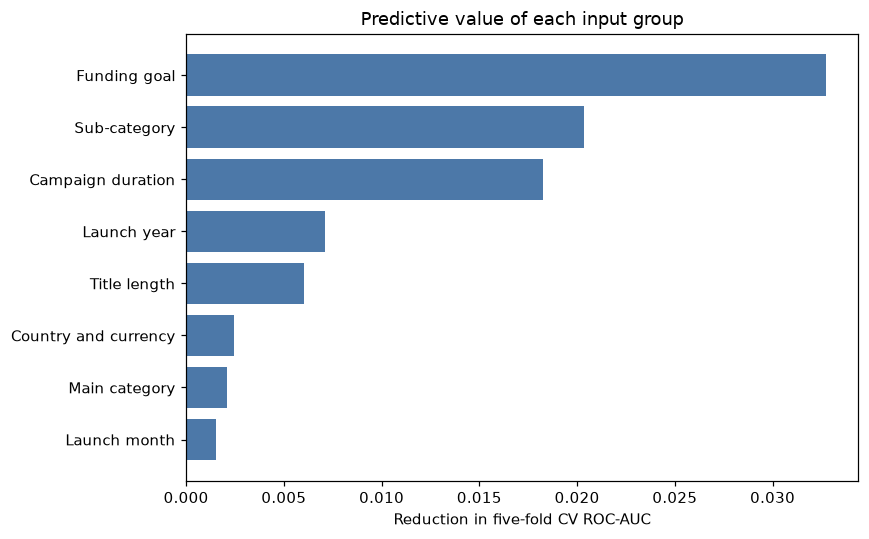

In [37]:
# Define the columns belonging to each family of pre-launch inputs.
feature_groups = {
    "Funding goal": ["log_goal_usd"],
    "Main category": [
        column for column in X_expanded.columns
        if column.startswith("category_")
    ],
    "Sub-category": [
        column for column in X_expanded.columns
        if column.startswith("sub_category_")
    ],
    "Campaign duration": ["duration_days"],
    "Title length": ["name_chars", "name_words"],
    "Country and currency": [
        column for column in X_expanded.columns
        if column.startswith(("country_", "currency_"))
    ],
    "Launch year": [
        column for column in X_expanded.columns
        if column.startswith("year_")
    ],
    "Launch month": [
        column for column in X_expanded.columns
        if column.startswith("month_")
    ],
}

final_cv_auc = cv_results.loc[
    cv_results["Candidate"].eq("XGBoost depth 8 | expanded inputs"),
    "CV ROC_AUC",
].iloc[0]

ablation_rows = []
for group_name, group_columns in feature_groups.items():
    reduced_inputs = X_expanded.drop(columns=group_columns)
    reduced_auc, reduced_std = cross_validated_auc(
        lambda a, b, c: xgb_fit_predict(a, b, c, depth=8, rounds=300),
        reduced_inputs,
    )
    ablation_rows.append({
        "Removed input group": group_name,
        "CV ROC_AUC after removal": reduced_auc,
        "Reduction from full model": final_cv_auc - reduced_auc,
        "CV standard deviation": reduced_std,
    })
    print(
        f"Without {group_name:22s}: {reduced_auc:.4f} "
        f"(reduction {final_cv_auc - reduced_auc:+.4f})"
    )

feature_group_removal = pd.DataFrame(ablation_rows).sort_values(
    "Reduction from full model",
    ascending=False,
)
display(feature_group_removal.style.format({
    "CV ROC_AUC after removal": "{:.4f}",
    "Reduction from full model": "{:+.4f}",
    "CV standard deviation": "{:.4f}",
}))

plot_ablation = feature_group_removal.sort_values("Reduction from full model")
plt.figure(figsize=(8, 5))
plt.barh(
    plot_ablation["Removed input group"],
    plot_ablation["Reduction from full model"],
    color="#4C78A8",
)
plt.axvline(0, color="grey", linewidth=1)
plt.xlabel("Reduction in five-fold CV ROC-AUC")
plt.ylabel("")
plt.title("Predictive value of each input group")
plt.tight_layout()
plt.show()

This removal exercise measures predictive contribution, not causality. Correlated inputs may substitute for one another, so a small reduction does not necessarily mean that an input is unimportant in every application.

# 14. Translate the model into business action

Information available before launch provides a meaningful prediction of campaign success. The selected model's greatest value is not simply producing a success-or-failure label: it assigns every campaign a predicted probability of success, allowing the platform to rank campaigns by risk.

A platform could use that ranking before launch to identify campaigns that may benefit from additional guidance on funding-goal realism, the historical performance of similar categories, campaign duration, launch timing, and general preparation. The following analyses show how the ranking could support that process.


## 14.1 ROC curves

The ROC curve shows, across all possible thresholds, how many successful campaigns a model identifies against how many failed campaigns it incorrectly classifies as successful. The area under this curve is the ROC-AUC used throughout the project.


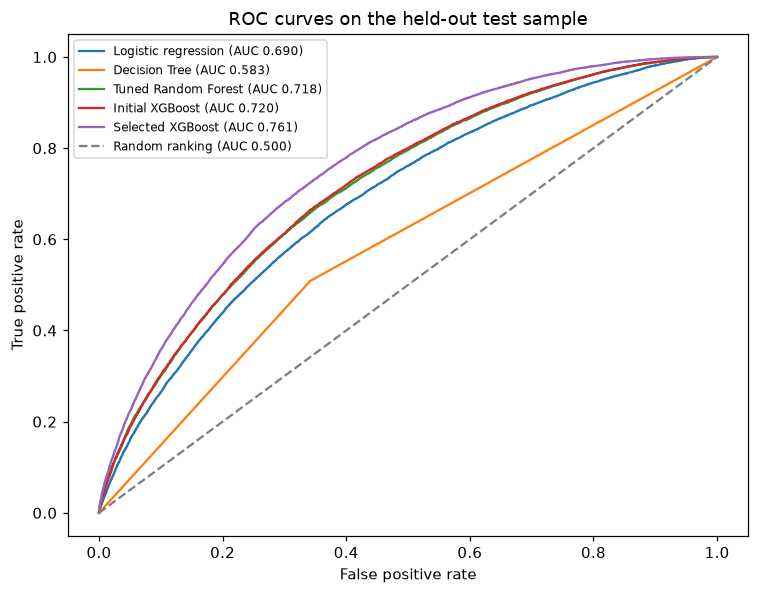

In [38]:
curves = {
    "Logistic regression": extended_probability,
    "Decision Tree": tree_probability,
    "Tuned Random Forest": tuned_forest_probability,
    "Initial XGBoost": xgb_probability,
    "Selected XGBoost": final_probability,
}
plt.figure(figsize=(7, 5.5))
for label, probability in curves.items():
    fpr, tpr, _ = roc_curve(Y_test, probability)
    plt.plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(Y_test, probability):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random ranking (AUC 0.500)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on the held-out test sample")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 14.2 Risk deciles

A crowdfunding platform does not need to rely only on a yes/no prediction. We sort the test campaigns from the lowest to the highest predicted probability of success and divide them into ten equally sized groups. This shows whether the model concentrates failures in its highest-risk groups.


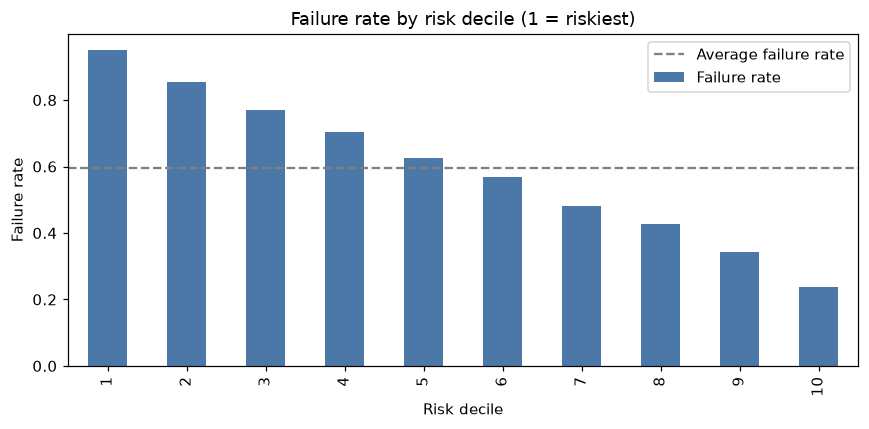

,Risk decile,Failure rate
0,1,95.1%
1,2,85.4%
2,3,76.9%
3,4,70.3%
4,5,62.5%
5,6,57.0%
6,7,48.2%
7,8,42.7%
8,9,34.4%
9,10,23.7%


In [39]:
risk_order = np.argsort(final_probability, kind="stable")  # riskiest campaigns first
y_test_array = Y_test.to_numpy()
deciles = np.array_split(risk_order, 10)
lift_table = pd.DataFrame({
    "Risk decile": range(1, 11),
    "Failure rate": [1 - y_test_array[d].mean() for d in deciles],
})

lift_table.plot(x="Risk decile", y="Failure rate", kind="bar", legend=False, color="#4C78A8", figsize=(8, 4))
plt.axhline(1 - y_test_array.mean(), color="grey", linestyle="--", label="Average failure rate")
plt.title("Failure rate by risk decile (1 = riskiest)")
plt.ylabel("Failure rate")
plt.legend()
plt.tight_layout()
plt.show()
display(lift_table.style.format({"Failure rate": "{:.1%}"}))

## 14.3 Choose a coaching threshold

The platform can set its intervention threshold according to coaching capacity. For example, if the team can support one campaign in five, it can select the 20% with the lowest predicted probability of success.


In [40]:
coaching_rows = []
for share in (0.10, 0.20, 0.30):
    coached = risk_order[: int(round(share * len(y_test_array)))]
    coaching_rows.append({
        "Coach the riskiest": f"{share:.0%}",
        "Failure rate among coached": 1 - y_test_array[coached].mean(),
        "Share of all failures reached": (y_test_array[coached] == 0).sum() / (y_test_array == 0).sum(),
    })
coaching_table = pd.DataFrame(coaching_rows)
display(coaching_table.style.format({"Failure rate among coached": "{:.1%}",
                                     "Share of all failures reached": "{:.1%}"}))

,Coach the riskiest,Failure rate among coached,Share of all failures reached
0,10%,95.1%,15.9%
1,20%,90.2%,30.3%
2,30%,85.8%,43.2%


# 15. Robustness checks


## 15.1 How stable is the improvement over the tuned Random Forest?

The selected model performs better than the tuned Random Forest on the held-out test sample. We resample the test campaigns 1,000 times using a bootstrap to examine whether that ROC-AUC difference is stable across repeated samples.


In [41]:
rng = np.random.default_rng(RANDOM_STATE)

selected_auc_samples = []
difference_from_logit = []
difference_from_forest = []

for _ in range(1000):
    sample_indices = rng.integers(0, len(y_test_array), len(y_test_array))
    sampled_outcome = y_test_array[sample_indices]

    # A bootstrap sample containing only one outcome cannot produce ROC-AUC.
    if np.unique(sampled_outcome).size < 2:
        continue

    selected_auc = roc_auc_score(
        sampled_outcome,
        final_probability[sample_indices],
    )
    logit_auc = roc_auc_score(
        sampled_outcome,
        expanded_logit_probability[sample_indices],
    )
    forest_auc = roc_auc_score(
        sampled_outcome,
        tuned_forest_probability[sample_indices],
    )

    selected_auc_samples.append(selected_auc)
    difference_from_logit.append(selected_auc - logit_auc)
    difference_from_forest.append(selected_auc - forest_auc)


def bootstrap_summary(values):
    values = np.asarray(values)
    low, high = np.percentile(values, [2.5, 97.5])
    return values.mean(), low, high


selected_mean, selected_low, selected_high = bootstrap_summary(
    selected_auc_samples
)
logit_mean, logit_low, logit_high = bootstrap_summary(
    difference_from_logit
)
forest_mean, forest_low, forest_high = bootstrap_summary(
    difference_from_forest
)

bootstrap_results = pd.DataFrame({
    "Quantity": [
        "Selected XGBoost ROC_AUC",
        "Selected XGBoost minus expanded Logistic Regression",
        "Selected XGBoost minus tuned Random Forest",
    ],
    "Estimate": [selected_mean, logit_mean, forest_mean],
    "95% interval lower": [selected_low, logit_low, forest_low],
    "95% interval upper": [selected_high, logit_high, forest_high],
})

display(bootstrap_results.style.format({
    "Estimate": "{:.4f}",
    "95% interval lower": "{:.4f}",
    "95% interval upper": "{:.4f}",
}))

,Quantity,Estimate,95% interval lower,95% interval upper
0,Selected XGBoost ROC_AUC,0.7610,0.7574,0.7647
1,Selected XGBoost minus expanded Logistic Regression,0.0309,0.0287,0.0330
2,Selected XGBoost minus tuned Random Forest,0.0428,0.0401,0.0454


The paired bootstrap resamples historical test campaigns while holding fitted predictions fixed. It measures test-sample uncertainty conditional on this fitted model; it does not include uncertainty from model selection or retraining. The forest comparison uses baseline inputs, whereas the logistic comparison uses expanded inputs.

## 15.2 Future-period validation

The analysis next trains on campaigns launched through 2016 and evaluate on campaigns launched in 2017. Launch-year dummy variables are removed because the model cannot learn a 2017 coefficient from earlier years.

In [42]:
launch_year_number = data["launched"].dt.year.to_numpy()
past = launch_year_number <= 2016
future = launch_year_number == 2017
X_no_year = X_expanded.filter(regex="^(?!year_)")

future_probability = xgb_fit_predict(
    X_no_year[past],
    data["success"][past],
    X_no_year[future],
    depth=8,
    rounds=300,
)
print(f"Campaigns launched in 2017: {future.sum():,}")
print(
    "ROC-AUC on 2017 campaigns (trained on 2009–2016): "
    f"{roc_auc_score(data['success'][future], future_probability):.4f}"
)

random_probability = xgb_fit_predict(
    X_no_year.loc[train_rows],
    Y_train,
    X_no_year.loc[test_rows],
    depth=8,
    rounds=300,
)
print(
    "ROC-AUC using the same inputs and the random split: "
    f"{roc_auc_score(Y_test, random_probability):.4f}"
)

Campaigns launched in 2017: 43,419
ROC-AUC on 2017 campaigns (trained on 2009–2016): 0.7695


ROC-AUC using the same inputs and the random split: 0.7524


The model retains useful ranking performance on campaigns launched later in time. This is a temporal robustness check rather than a completely untouched prospective test, because the model settings were developed during the wider analysis. Campaigns launched late in 2017 may also be under-represented because some were still live when the dataset was collected.


## 15.3 Sensitivity analysis for canceled campaigns

Canceled campaigns are excluded from the main binary outcome because a cancellation is not the same event as failing to reach a funding goal. As a sensitivity check, we score them with the already fitted model and then temporarily treat them as failures to see whether the overall ranking changes.

In [43]:
# Reproduce the same pre-launch features for canceled campaigns.
canceled = raw_data.loc[raw_data["state"].eq("canceled")].copy()
canceled["launched"] = pd.to_datetime(canceled["launched"])
canceled["deadline"] = pd.to_datetime(canceled["deadline"])
canceled["duration_days"] = (
    canceled["deadline"] - canceled["launched"]
).dt.total_seconds().div(86_400)
canceled["launch_year"] = canceled["launched"].dt.year.astype(str)
canceled["launch_month"] = canceled["launched"].dt.month.astype(str)
canceled["log_goal_usd"] = np.log1p(canceled["usd_goal_real"])
canceled["country_clean"] = canceled["country"].replace({'N,0"': "Unknown"})

canceled_name = canceled["name"].fillna("").astype(str)
canceled["name_chars"] = canceled_name.str.len()
canceled["name_words"] = (
    canceled_name.str.split().str.len().fillna(0).astype(int)
)

canceled_original = pd.get_dummies(
    canceled[[
        "main_category",
        "log_goal_usd",
        "country_clean",
        "currency",
        "duration_days",
        "launch_year",
        "launch_month",
    ]],
    prefix=["category", "country", "currency", "year", "month"],
    columns=[
        "main_category",
        "country_clean",
        "currency",
        "launch_year",
        "launch_month",
    ],
    dtype=int,
)

canceled_expanded = pd.concat(
    [
        canceled_original,
        pd.get_dummies(
            canceled["category"],
            prefix="sub_category",
            dtype=int,
        ),
        canceled[["name_chars", "name_words"]],
    ],
    axis=1,
)

# Align the canceled campaigns to the exact columns used by the final model.
canceled_expanded = canceled_expanded.reindex(
    columns=X_final_train.columns,
    fill_value=0,
)
canceled_probability = final_xgb_model.predict(
    xgb.DMatrix(
        canceled_expanded,
        feature_names=canceled_expanded.columns.tolist(),
    )
)

probability_by_outcome = pd.DataFrame({
    "Campaign group": [
        "Failed test campaigns",
        "Successful test campaigns",
        "Canceled campaigns",
    ],
    "Campaigns": [
        int((y_test_array == 0).sum()),
        int((y_test_array == 1).sum()),
        len(canceled_probability),
    ],
    "Mean predicted success probability": [
        final_probability[y_test_array == 0].mean(),
        final_probability[y_test_array == 1].mean(),
        canceled_probability.mean(),
    ],
})
display(probability_by_outcome.style.format({
    "Mean predicted success probability": "{:.1%}",
}))

# Temporarily count canceled campaigns as failures without retraining the model.
sensitivity_outcome = np.concatenate([
    y_test_array,
    np.zeros(len(canceled_probability), dtype=int),
])
sensitivity_probability = np.concatenate([
    final_probability,
    canceled_probability,
])
sensitivity_prediction = (sensitivity_probability >= 0.50).astype(int)

print(
    "ROC-AUC when canceled campaigns are treated as failures: "
    f"{roc_auc_score(sensitivity_outcome, sensitivity_probability):.4f}"
)
print(
    "Accuracy when canceled campaigns are treated as failures: "
    f"{accuracy_score(sensitivity_outcome, sensitivity_prediction):.1%}"
)

,Campaign group,Campaigns,Mean predicted success probability
0,Failed test campaigns,39544,32.5%
1,Successful test campaigns,26791,52.2%
2,Canceled campaigns,38779,33.9%


ROC-AUC when canceled campaigns are treated as failures: 0.7515
Accuracy when canceled campaigns are treated as failures: 72.4%


This check is deliberately labelled a sensitivity analysis: some canceled projects may have been withdrawn for reasons unrelated to their likelihood of reaching the funding goal.

## 15.4 Does performance differ across campaign categories?

A single overall ROC-AUC can hide uneven performance. We therefore calculate ROC-AUC separately for each main category in the held-out test sample.

,Main category,Test campaigns,Success rate,ROC_AUC
13,Technology,5349,23.6%,0.822
8,Games,5618,45.1%,0.800
2,Crafts,1484,27.7%,0.775
9,Journalism,837,27.5%,0.763
7,Food,4438,27.2%,0.750
11,Photography,1996,34.3%,0.733
10,Music,9191,52.1%,0.725
5,Fashion,3961,27.9%,0.721
0,Art,5293,44.8%,0.721
12,Publishing,7094,34.9%,0.721


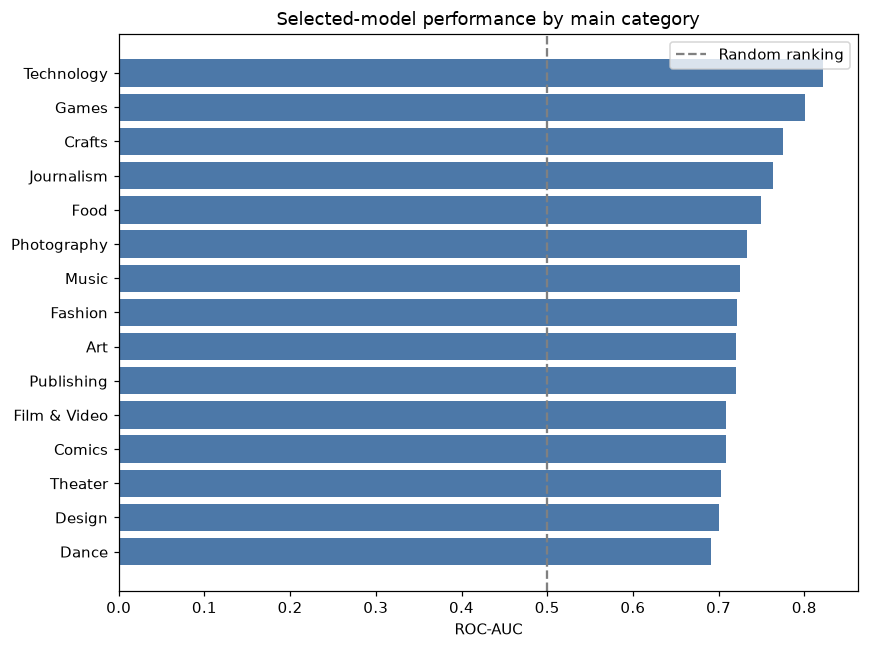

In [44]:
test_categories = data.loc[test_rows, "main_category"].to_numpy()
category_auc_rows = []

for category_name in sorted(np.unique(test_categories)):
    category_mask = test_categories == category_name
    category_outcome = y_test_array[category_mask]

    # ROC-AUC requires both successful and failed campaigns.
    if category_mask.sum() < 500 or np.unique(category_outcome).size < 2:
        continue

    category_auc_rows.append({
        "Main category": category_name,
        "Test campaigns": int(category_mask.sum()),
        "Success rate": category_outcome.mean(),
        "ROC_AUC": roc_auc_score(
            category_outcome,
            final_probability[category_mask],
        ),
    })

category_auc_results = pd.DataFrame(category_auc_rows).sort_values(
    "ROC_AUC",
    ascending=False,
)
display(category_auc_results.style.format({
    "Success rate": "{:.1%}",
    "ROC_AUC": "{:.3f}",
}))

plot_category_auc = category_auc_results.sort_values("ROC_AUC")
plt.figure(figsize=(8, 6))
plt.barh(
    plot_category_auc["Main category"],
    plot_category_auc["ROC_AUC"],
    color="#4C78A8",
)
plt.axvline(0.5, color="grey", linestyle="--", label="Random ranking")
plt.xlabel("ROC-AUC")
plt.ylabel("")
plt.title("Selected-model performance by main category")
plt.legend()
plt.tight_layout()
plt.show()

Category-level differences identify where model monitoring may be most useful. They should not be interpreted as evidence that belonging to a category causes stronger or weaker performance.

# 16. Limitations

- **Historical snapshot:** the data end around 2017; performance on current campaigns is unknown.
- **Point-in-time availability:** exchange-rate timing and revisions to campaign attributes have not been verified.
- **Development reuse:** early models were evaluated on the same random test split during development. The final CV selection and later presentation do not erase that reuse.
- **Non-nested selection:** Random Forest settings and candidate selection reuse training folds; CV scores are selection estimates, not unbiased estimates of the entire tuning procedure.
- **Temporal check:** the specification was developed using observations including 2017, so the later-period check is robustness evidence, not an untouched forecast.
- **Encoding:** dummy levels are derived from the full historical feature table; labels do not enter this encoding, but a deployment pipeline should learn its vocabulary on training data and handle unseen categories explicitly.
- **Outcome and coverage:** the main sample excludes canceled and unfinished campaigns. Creator history, campaign media, and promotional reach are unavailable.
- **Decision use:** risk concentration does not establish that coaching works, or which campaigns benefit most. A prospective evaluation and randomized support pilot would be needed.
- **Interpretation:** feature importance and associations are predictive, not causal.

# 17. Conclusion

In [45]:
selected_row = model_results.loc[
    model_results["Model"].eq("Selected XGBoost with expanded inputs")
].iloc[0]

print(f"Benchmark accuracy: {benchmark_accuracy:.1%}")
print(f"Selected-model accuracy: {selected_row['Accuracy']:.1%}")
print(f"Selected-model ROC-AUC: {selected_row['ROC_AUC']:.3f}")
print(
    "Accuracy improvement over the benchmark: "
    f"{selected_row['Accuracy'] - benchmark_accuracy:.1%}"
)
print(
    f"Failure rate in the riskiest 20%: "
    f"{coaching_table.loc[1, 'Failure rate among coached']:.1%} "
    f"(overall test-sample failure rate: {1 - y_test_array.mean():.1%})"
)

Benchmark accuracy: 59.6%
Selected-model accuracy: 69.8%
Selected-model ROC-AUC: 0.761
Accuracy improvement over the benchmark: 10.2%
Failure rate in the riskiest 20%: 90.2% (overall test-sample failure rate: 59.6%)


Launch-related campaign attributes contain useful but imperfect historical predictive information. The controlled comparison shows why input quality matters alongside model complexity. Calibration and risk concentration provide a more useful picture than accuracy alone.

These findings support further evaluation of a campaign-review ranking. They do not validate automatic approval/rejection, prove that coaching changes outcomes, or establish present-day performance.

In [46]:
# Export aggregate evidence, without campaign-level data or fitted models.
tables = {
    "model_comparison": model_results,
    "cross_validation": cv_results,
    "input_algorithm_comparison": controlled_comparison,
    "calibration": calibration_table,
    "feature_ablation": feature_group_removal,
    "risk_deciles": lift_table,
    "review_capacity": coaching_table,
    "bootstrap": bootstrap_results,
    "category_performance": category_auc_results,
}
for name, frame in tables.items():
    frame.to_csv(RESULTS / f"{name}.csv", index=False)
summary = {
    "raw_campaigns": len(raw_data), "analysis_campaigns": len(data),
    "train_campaigns": len(Y_train), "test_campaigns": len(Y_test),
    "selected_model": selected_model_name,
    "accuracy": accuracy_score(Y_test, final_prediction),
    "roc_auc": roc_auc_score(Y_test, final_probability),
    "brier_score": final_brier_score,
    "temporal_2017_auc": roc_auc_score(data["success"][future], future_probability),
    "random_no_year_auc": roc_auc_score(Y_test, random_probability),
    "data_sha256": DATA_SHA256,
    "python": platform.python_version(),
    "packages": {p: version(p) for p in ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "xgboost"]},
    "elapsed_seconds": round(time.perf_counter() - RUN_STARTED, 1),
}
(RESULTS / "run_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print(json.dumps(summary, indent=2))


{
  "raw_campaigns": 378661,
  "analysis_campaigns": 331675,
  "train_campaigns": 265340,
  "test_campaigns": 66335,
  "selected_model": "XGBoost depth 8 | expanded inputs",
  "accuracy": 0.6978065877741765,
  "roc_auc": 0.760872758751397,
  "brier_score": 0.19321615993976593,
  "temporal_2017_auc": 0.7695085943229136,
  "random_no_year_auc": 0.7523676258493932,
  "data_sha256": "4846177ce8cfacd06a6acf06cba663b9aa5f5f77e7d0debecf5bdc861a87e3cb",
  "python": "3.13.1",
  "packages": {
    "pandas": "3.0.6",
    "numpy": "2.5.3",
    "matplotlib": "3.11.2",
    "seaborn": "0.13.2",
    "scikit-learn": "1.9.1",
    "xgboost": "3.4.1"
  },
  "elapsed_seconds": 731.9
}
